# Artificial Intelligence & Machine Learning - Task 1
## Build & Evaluate a Linear Regression Model (House Price Predictor)

**Objective:** Introduce the end-to-end Machine Learning lifecycle: data loading, exploratory data analysis (EDA), preprocessing, train/test splitting, linear regression model training, performance evaluation, diagnostic residual analysis, and model persistence using the **California Housing dataset**.

### Table of Contents
1. **Environment Setup & Library Imports**
2. **Dataset Acquisition & Overview**
3. **Exploratory Data Analysis (EDA) & Visualizations**
4. **Data Preprocessing & Train-Test Splitting**
5. **Model Architecture & Training (Linear Regression)**
6. **Model Evaluation & Metric Analysis (MAE, RMSE, $R^2$)**
7. **Diagnostic Residual Analysis & Error Evaluation**
8. **Model Export & Live Inference Demo**
9. **Findings, Limitations & Improvement Roadmap**

### 1. Environment Setup & Library Imports
We begin by importing core numerical computing, data analysis, visualization, and machine learning modules from `numpy`, `pandas`, `matplotlib`, `seaborn`, and `scikit-learn`.

In [1]:
# Basic imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-Learn modules
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Display settings
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

print('All libraries imported successfully.')
print(f'Numpy version: {np.__version__}')
print(f'Pandas version: {pd.__version__}')
import sklearn; print(f'Scikit-Learn version: {sklearn.__version__}')

All libraries imported successfully.
Numpy version: 2.4.6
Pandas version: 3.0.6
Scikit-Learn version: 1.9.1


### 2. Dataset Acquisition & Overview
The California Housing dataset originates from the 1990 U.S. Census. It contains aggregated demographic and geographic metrics for 20,640 census block groups (districts) in California.

- **Predictor Features (8):**
  1. `MedInc`: Median income in block group (in tens of thousands of USD, e.g. 3.5 = $35,000)
  2. `HouseAge`: Median house age in block group (years)
  3. `AveRooms`: Average number of rooms per household
  4. `AveBedrms`: Average number of bedrooms per household
  5. `Population`: Block group total population
  6. `AveOccup`: Average number of household members
  7. `Latitude`: Block group latitude
  8. `Longitude`: Block group longitude
- **Target Variable:**
  - `MedHouseVal`: Median house value for California districts, measured in hundreds of thousands of dollars ($100,000s, e.g., 2.0 = $200,000).

In [2]:
# Load dataset from local CSV or fetch directly from scikit-learn
csv_path = 'california_housing.csv'
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
else:
    data = fetch_california_housing(as_frame=True)
    df = pd.concat([data.data, data.target.rename('MedHouseVal')], axis=1)
    df.to_csv(csv_path, index=False)

print(f'Dataset Shape: {df.shape}')
print('First 5 Records:')
print(df.head())

Dataset Shape: (20640, 9)
First 5 Records:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  MedHouseVal
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88    -122.23        4.526
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86    -122.22        3.585
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85    -122.24        3.521
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85    -122.25        3.413
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85    -122.25        3.422


### 3. Exploratory Data Analysis (EDA)
Before training our regression model, we inspect summary statistics, missing data, feature distributions, geographic pricing trends, and correlation relationships.

In [3]:
# Data Quality & Summary Statistics
print('=== Missing Values Check ===')
print(df.isnull().sum())
print(f'\nTotal duplicate rows: {df.duplicated().sum()}')
print('\n=== Summary Statistics ===')
print(df.describe())

=== Missing Values Check ===
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Total duplicate rows: 0

=== Summary Statistics ===
             MedInc      HouseAge      AveRooms     AveBedrms    Population      AveOccup      Latitude     Longitude   MedHouseVal
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000
mean       3.870671     28.639486      5.429000      1.096675   1425.476744      3.070655     35.631861   -119.569704      2.068558
std        1.899822     12.585558      2.474173      0.473911   1132.462122     10.386050      2.135952      2.003532      1.153956
min        0.499900      1.000000      0.846154      0.333333      3.000000      0.692308     32.540000   -124.350000      0.149990
25%        2.563400     18.000000      4.440716      1.006079    787.000000      2.429741   

#### Visualizing Target Variable Distribution
Notice that `MedHouseVal` has an artificial upper cap at **5.00001** ($500,000), where all homes priced at or above $500,000 were clamped during data collection.

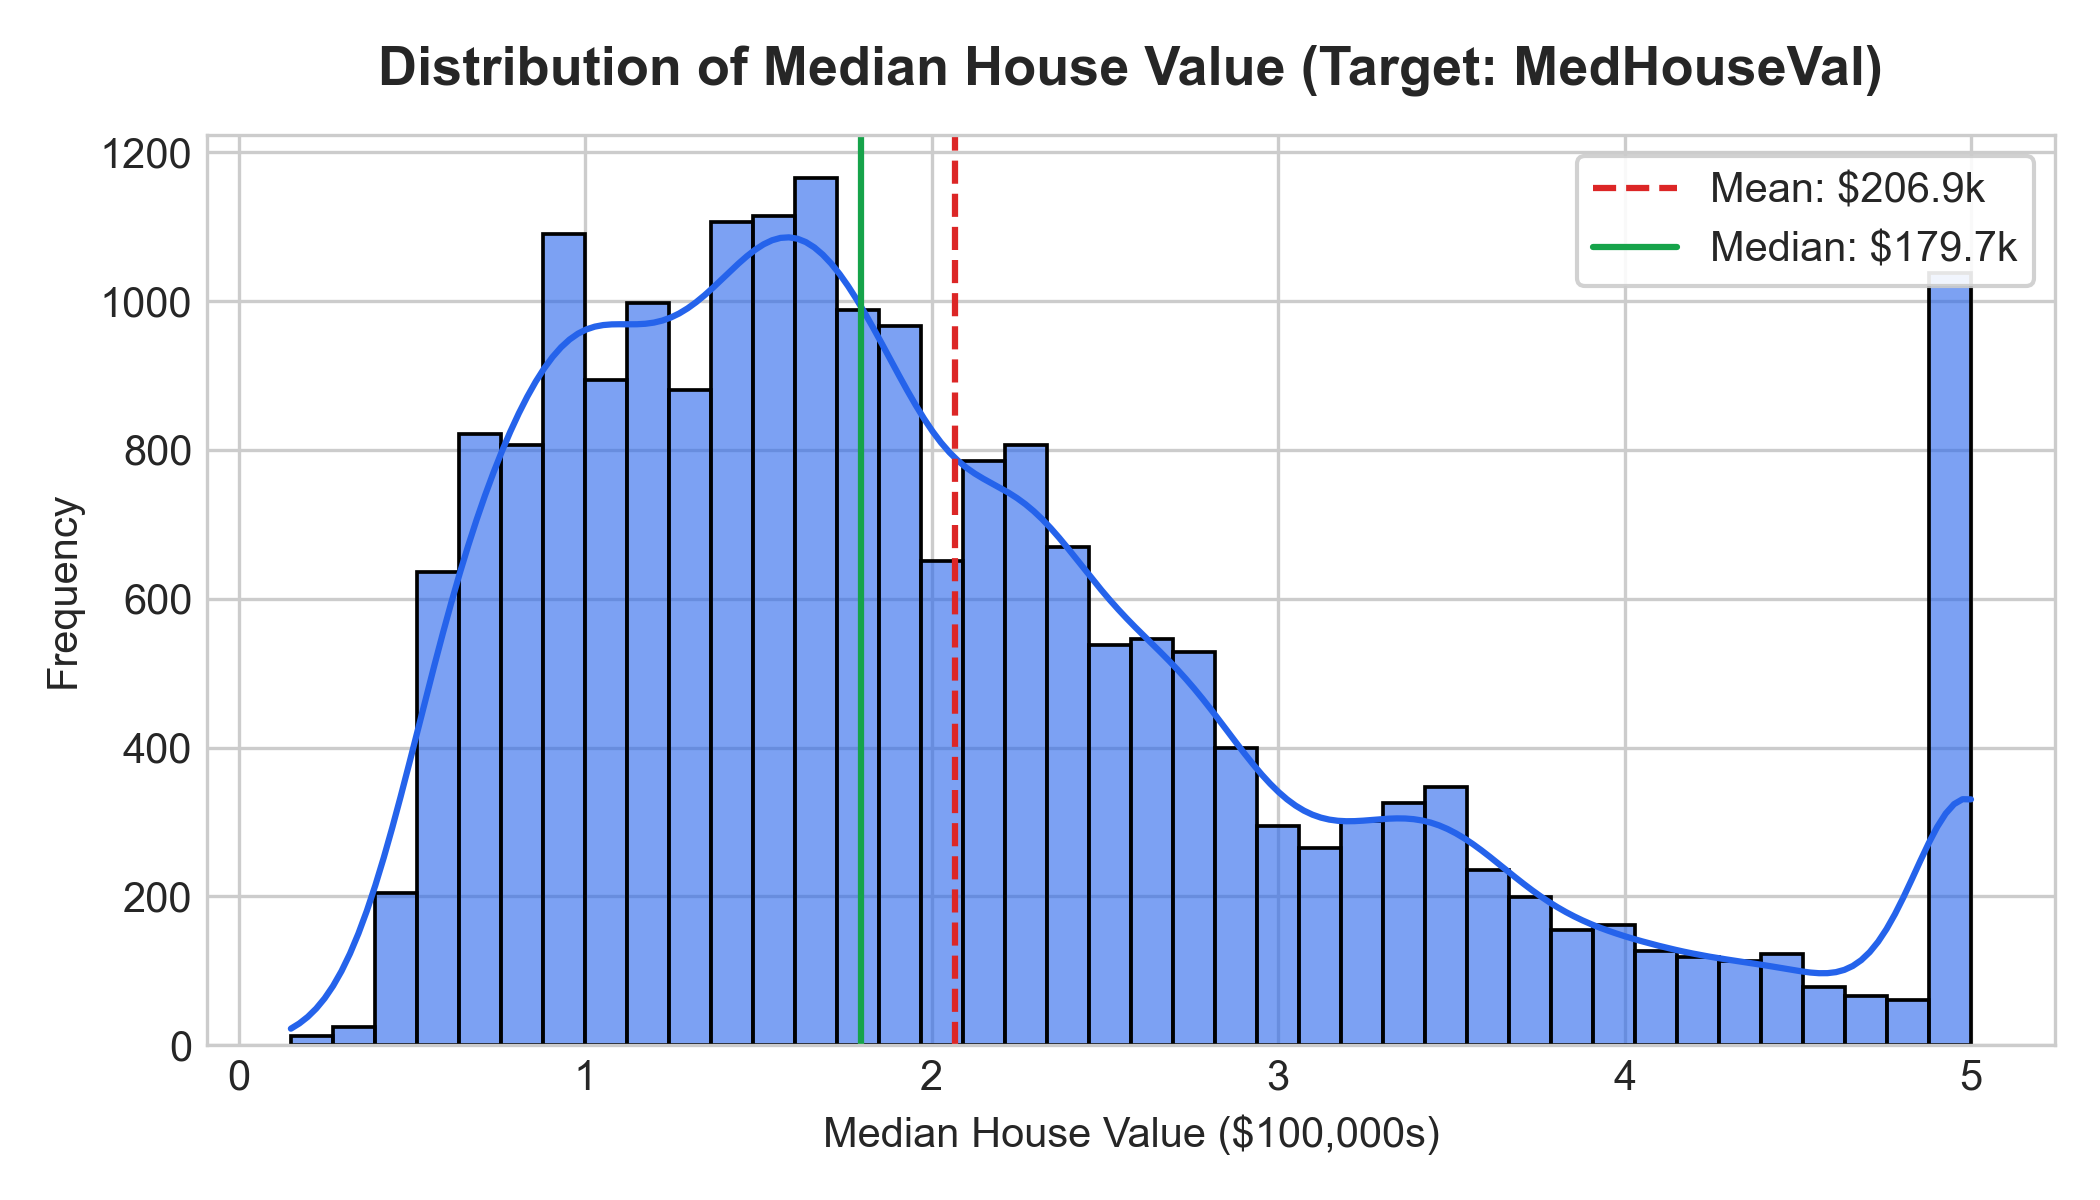

In [4]:
# Target Distribution Plot
plt.figure(figsize=(8, 4.5), dpi=150)
sns.histplot(df['MedHouseVal'], kde=True, color='#2563eb', bins=40, alpha=0.6)
plt.axvline(df['MedHouseVal'].mean(), color='#dc2626', linestyle='--', linewidth=1.8, label=f'Mean: ${df["MedHouseVal"].mean()*100:.1f}k')
plt.axvline(df['MedHouseVal'].median(), color='#16a34a', linestyle='-', linewidth=1.8, label=f'Median: ${df["MedHouseVal"].median()*100:.1f}k')
plt.title('Distribution of Median House Value (Target: MedHouseVal)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Median House Value ($100,000s)', fontsize=11)
plt.ylabel('Frequency', fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

#### Feature Correlation Analysis
Next, we compute the Pearson correlation matrix to identify which features possess the strongest linear association with home prices.

Correlation of features with MedHouseVal:
MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64


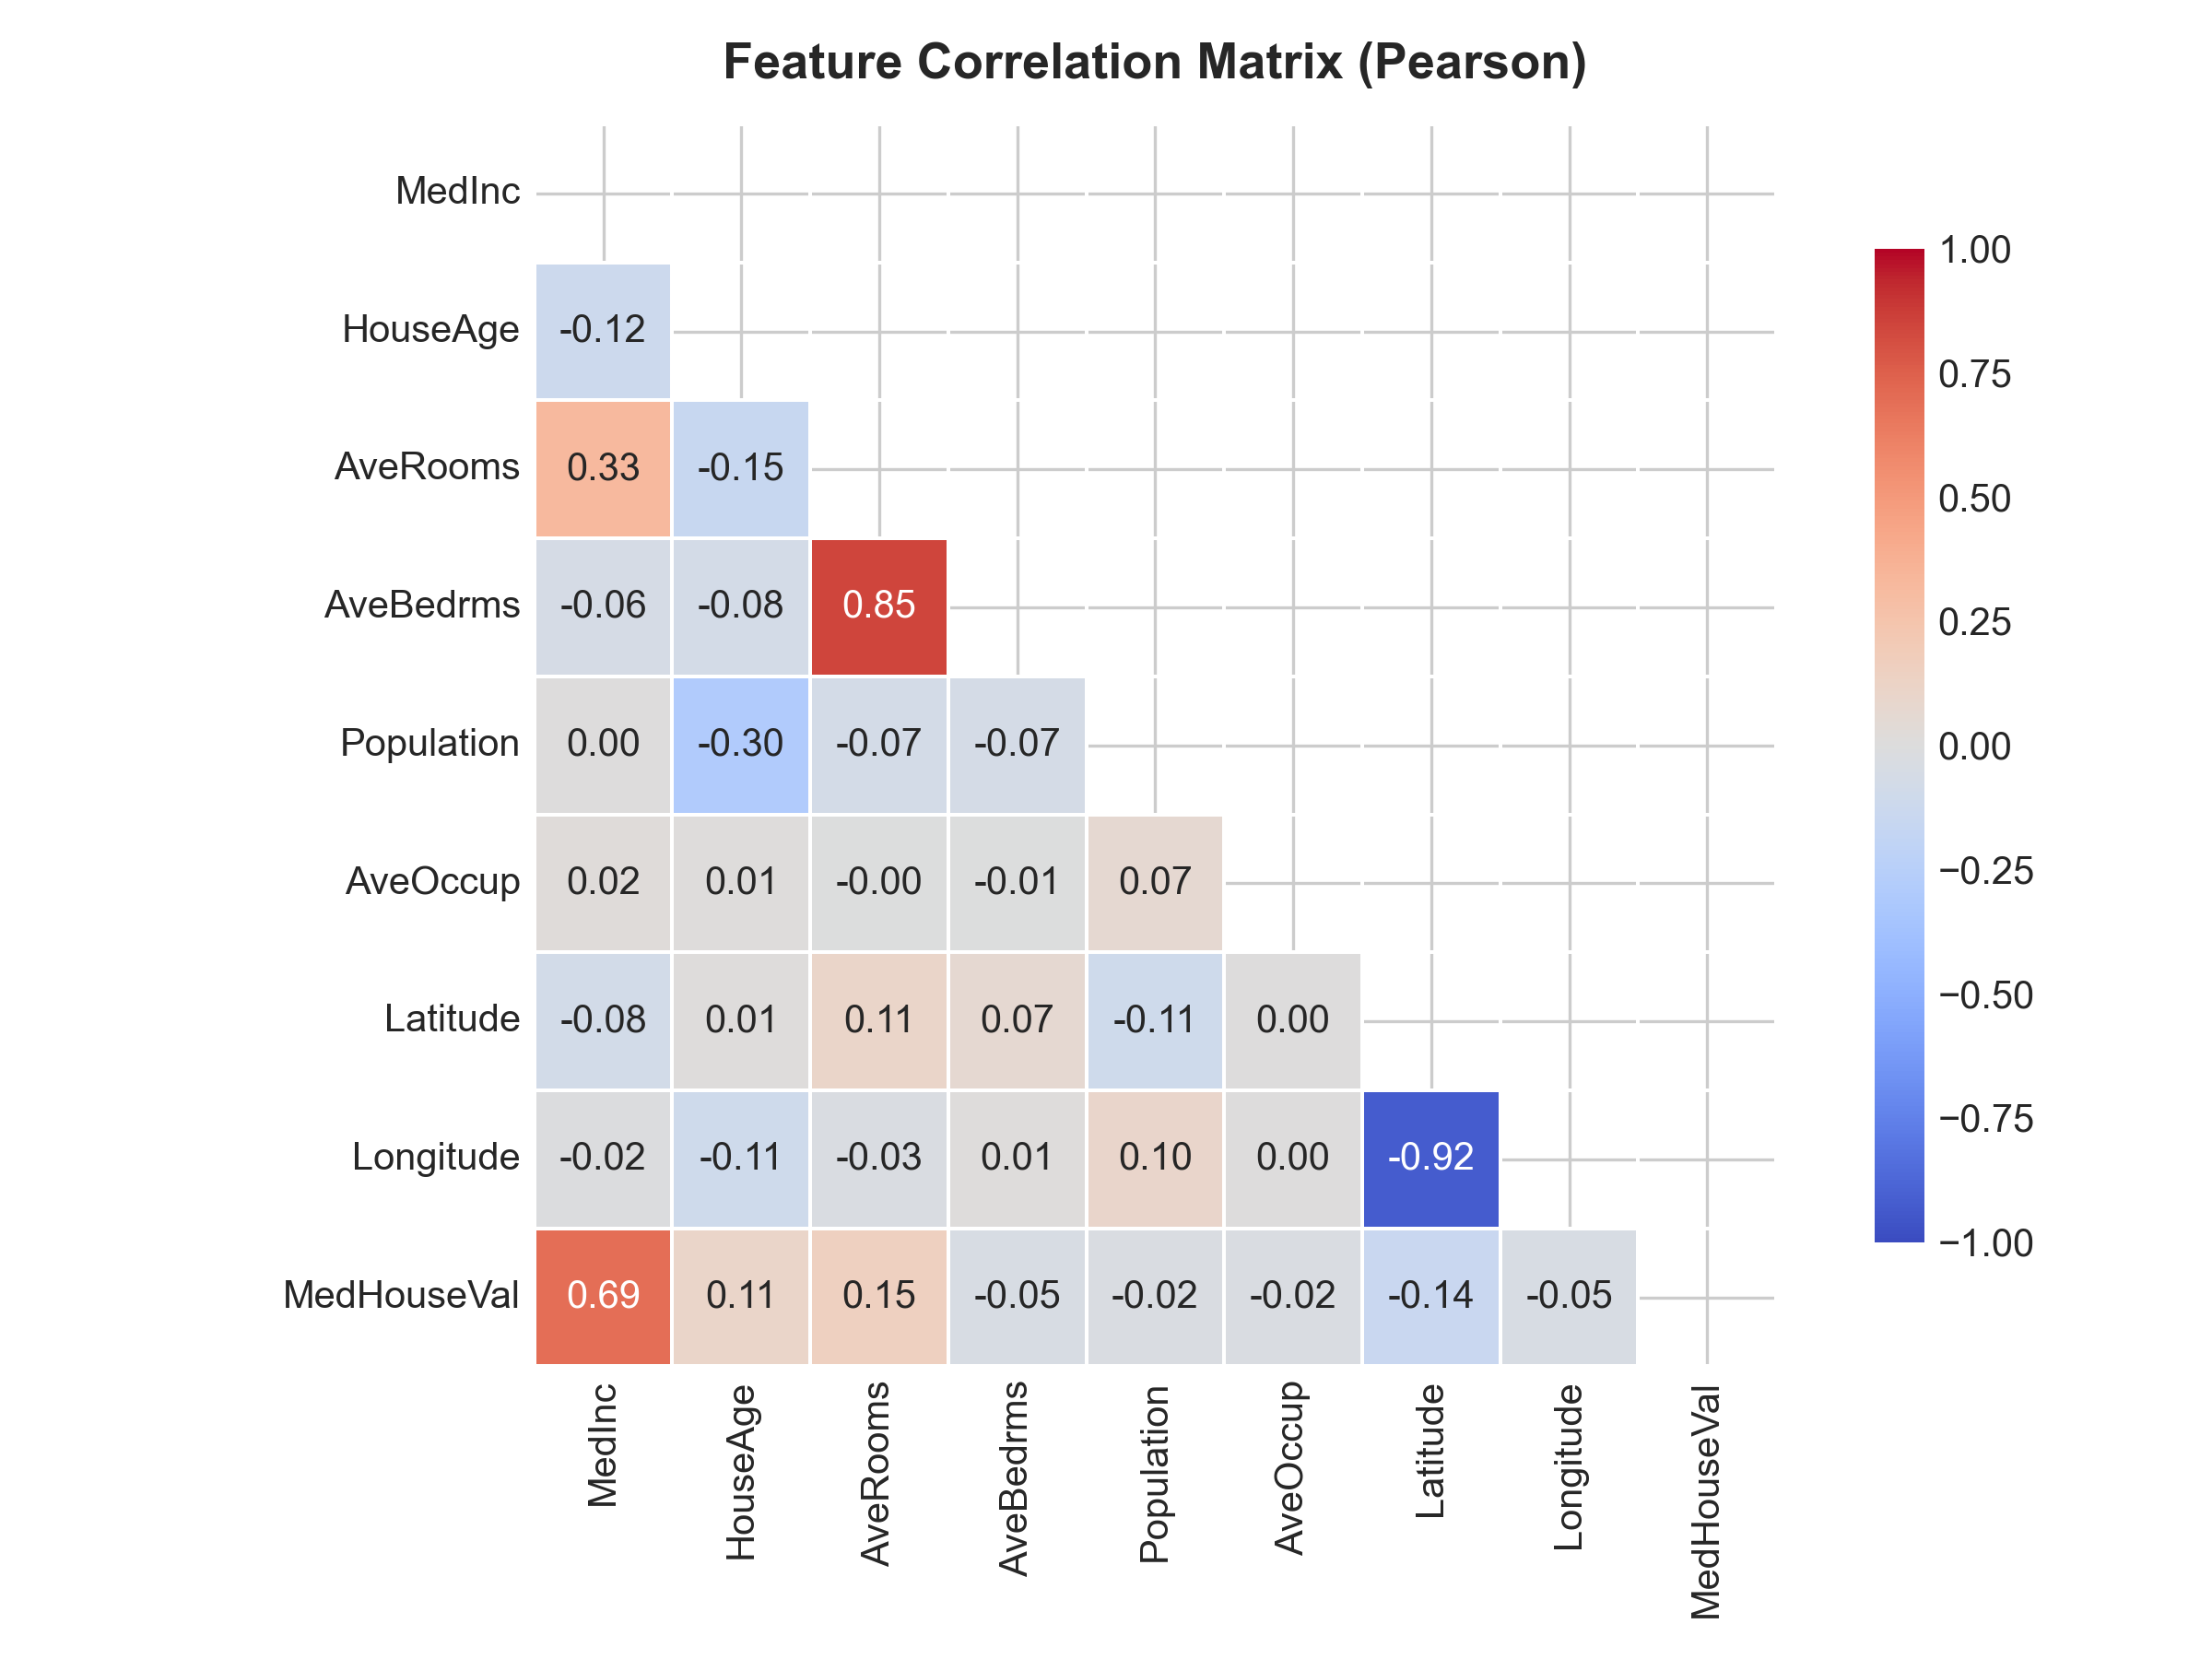

In [5]:
# Correlation Heatmap
corr = df.corr()
print('Correlation of features with MedHouseVal:')
print(corr['MedHouseVal'].sort_values(ascending=False))

plt.figure(figsize=(9, 6.5), dpi=150)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, mask=mask, square=True, linewidths=0.5)
plt.title('Feature Correlation Matrix (Pearson)', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

#### Geographic Pricing Map & Income Impact
The two visualizations below demonstrate the spatial and socio-economic dynamics of California housing:
1. **Coastal and Metropolitan Clusters:** The highest housing prices (yellow/green) concentrate along the Pacific coastline, the San Francisco Bay Area, and Greater Los Angeles.
2. **Median Income:** A strong, positive linear trend ($r = 0.69$) connects district income levels to home prices.

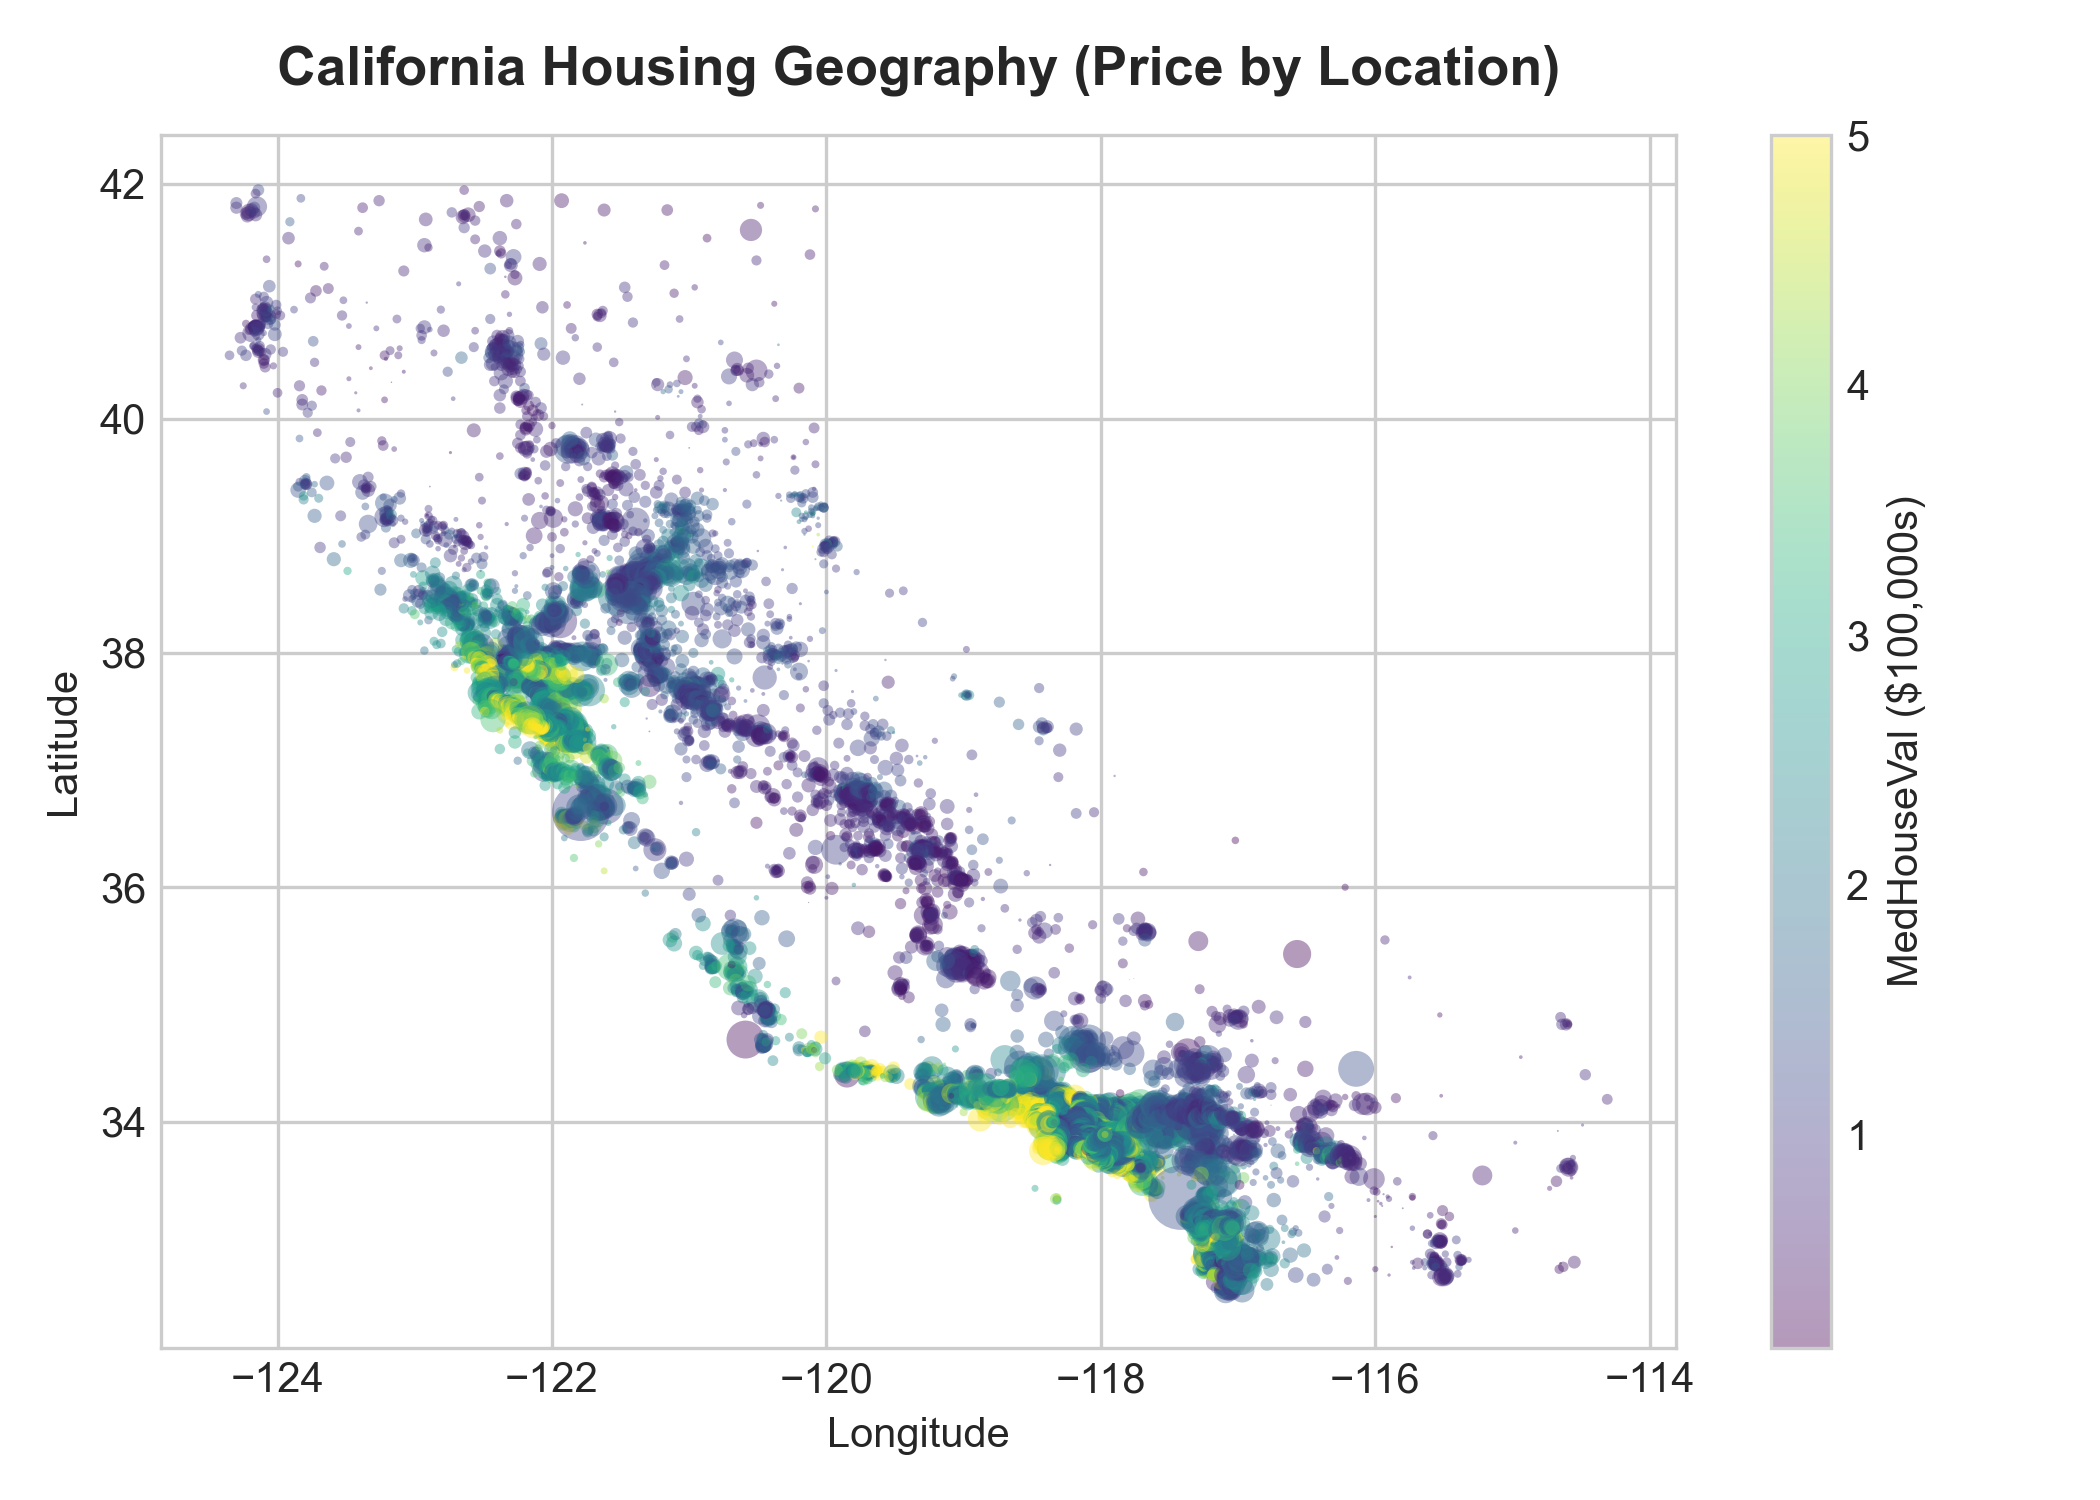

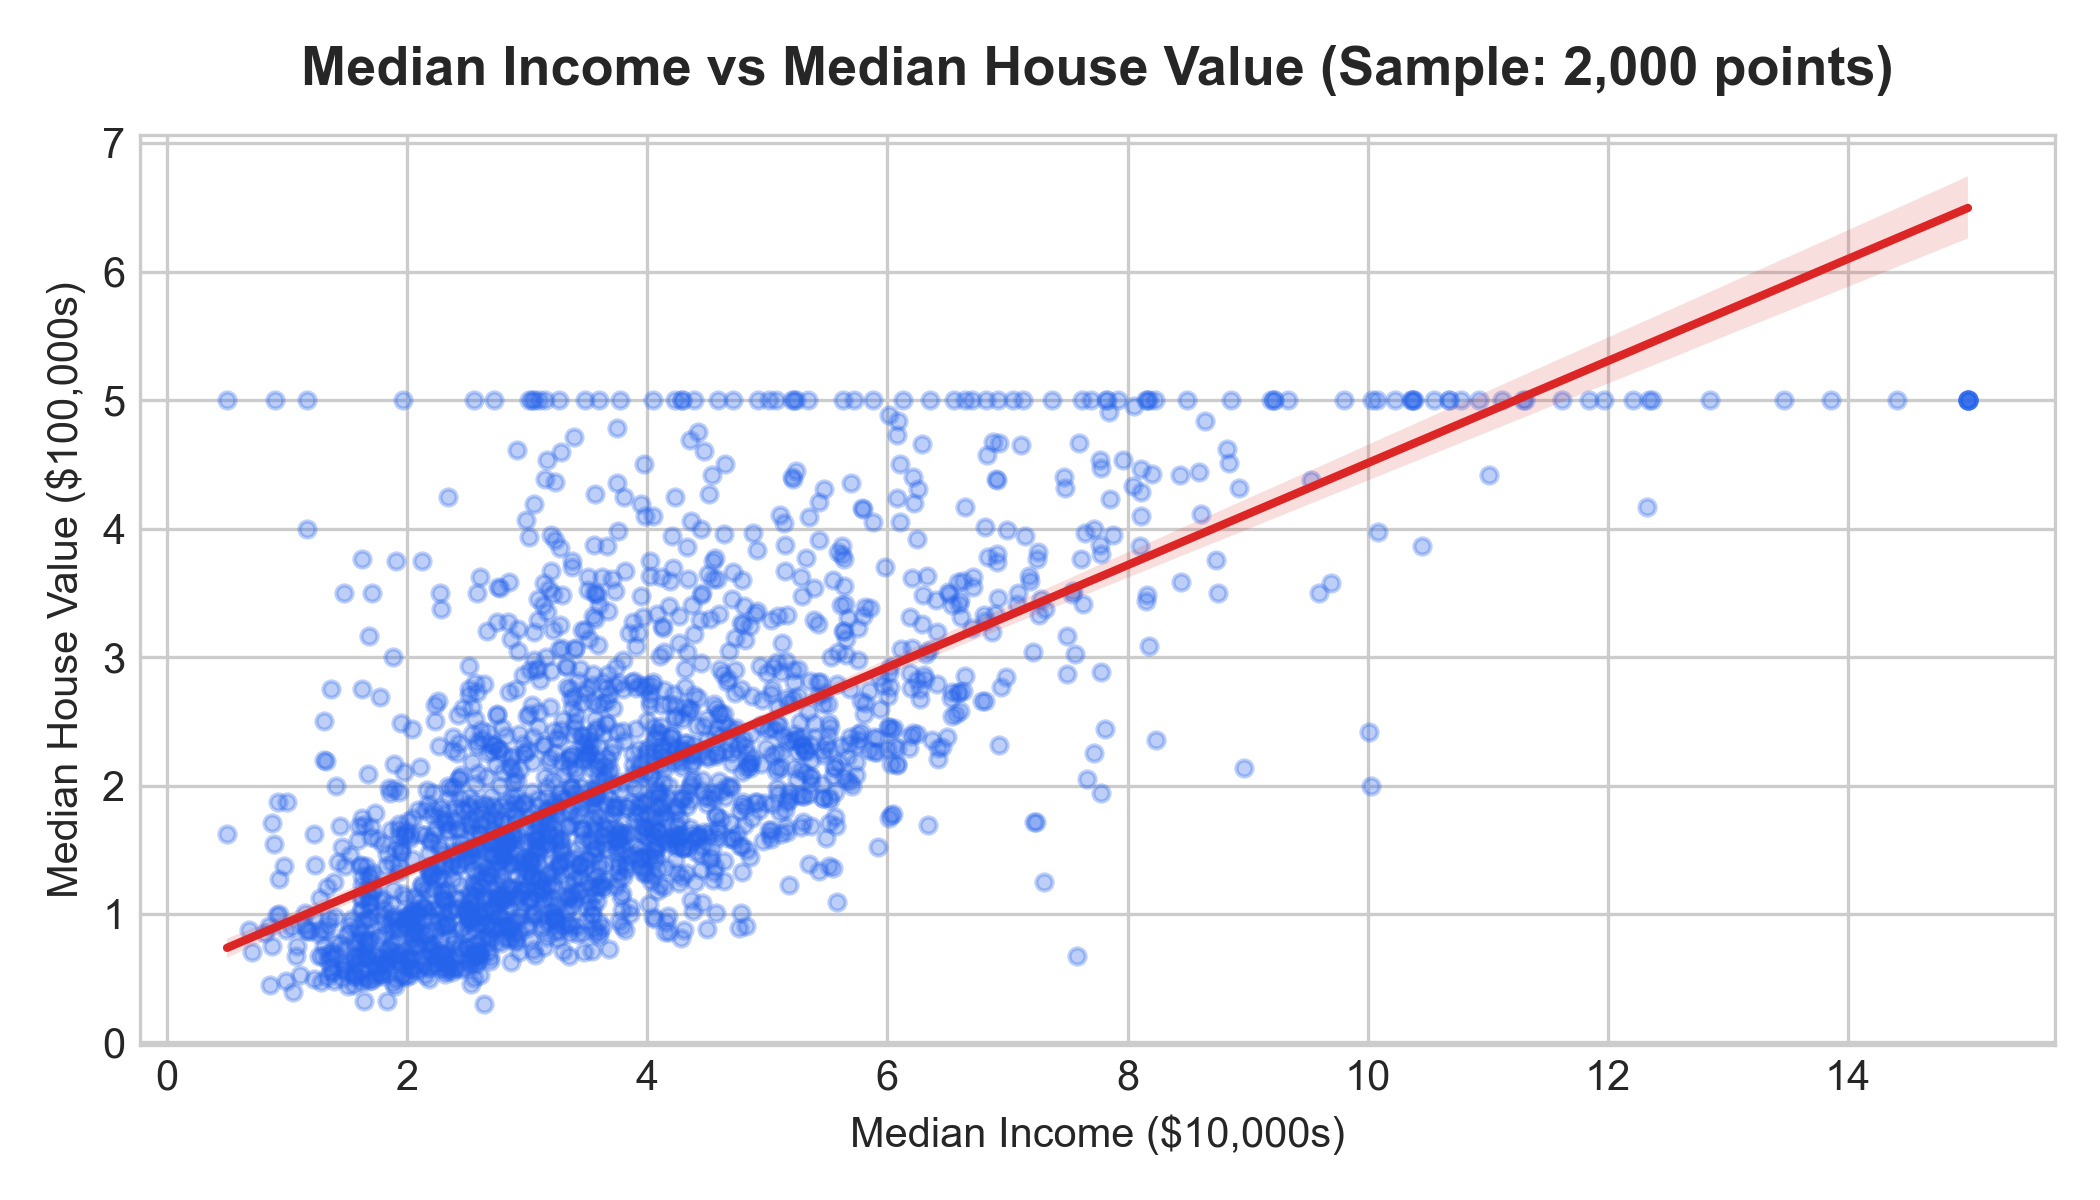

In [6]:
# California Housing Geography Plot
plt.figure(figsize=(8, 5.5), dpi=150)
scatter = plt.scatter(df['Longitude'], df['Latitude'], c=df['MedHouseVal'], cmap='viridis', alpha=0.4, s=df['Population']/150)
cbar = plt.colorbar(scatter)
cbar.set_label('MedHouseVal ($100,000s)', fontsize=10)
plt.title('California Housing Geography (Price by Location)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Longitude', fontsize=10)
plt.ylabel('Latitude', fontsize=10)
plt.tight_layout()
plt.show()

# Income vs Price Scatter Plot
plt.figure(figsize=(8, 4.5), dpi=150)
sns.regplot(data=df.sample(2000, random_state=42), x='MedInc', y='MedHouseVal',
            scatter_kws={'alpha': 0.3, 'color': '#2563eb', 's': 15},
            line_kws={'color': '#dc2626', 'linewidth': 2})
plt.title('Median Income vs Median House Value (Sample: 2,000 points)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Median Income ($10,000s)', fontsize=10)
plt.ylabel('Median House Value ($100,000s)', fontsize=10)
plt.tight_layout()
plt.show()

### 4. Data Preprocessing & Train-Test Splitting
We separate the feature matrix $X$ from the target vector $y = \text{MedHouseVal}$.
We then perform an **80/20 train/test split** using `train_test_split` with a fixed `random_state=42` to guarantee exact reproducibility.

In [7]:
# Separate features and target
X = df.drop(columns='MedHouseVal')
y = df['MedHouseVal']

# Train/Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f'Features Shape (X): {X.shape}')
print(f'Target Shape (y): {y.shape}')
print(f'Training set size: {len(X_train):,} samples ({len(X_train)/len(X):.1%})')
print(f'Testing set size:  {len(X_test):,} samples ({len(X_test)/len(X):.1%})')

Features Shape (X): (20640, 8)
Target Shape (y): (20640,)
Training set size: 16,512 samples (80.0%)
Testing set size:  4,128 samples (20.0%)


### 5. Model Architecture & Training (Linear Regression)
We instantiate and fit a multiple Ordinary Least Squares (OLS) `LinearRegression` model:

$$\hat{y} = \beta_0 + \sum_{i=1}^{8} \beta_i X_i$$

Where $\beta_0$ represents the intercept and $\beta_i$ represents the partial regression coefficient for feature $i$.

Model Intercept (beta_0): -37.0233

Model Coefficients:
      Feature  Coefficient
0      MedInc     0.448884
1    HouseAge     0.009724
4  Population    -0.000002
5    AveOccup    -0.003526
2    AveRooms    -0.123323
7   Longitude    -0.434514
6    Latitude    -0.433708
3   AveBedrms     0.783145


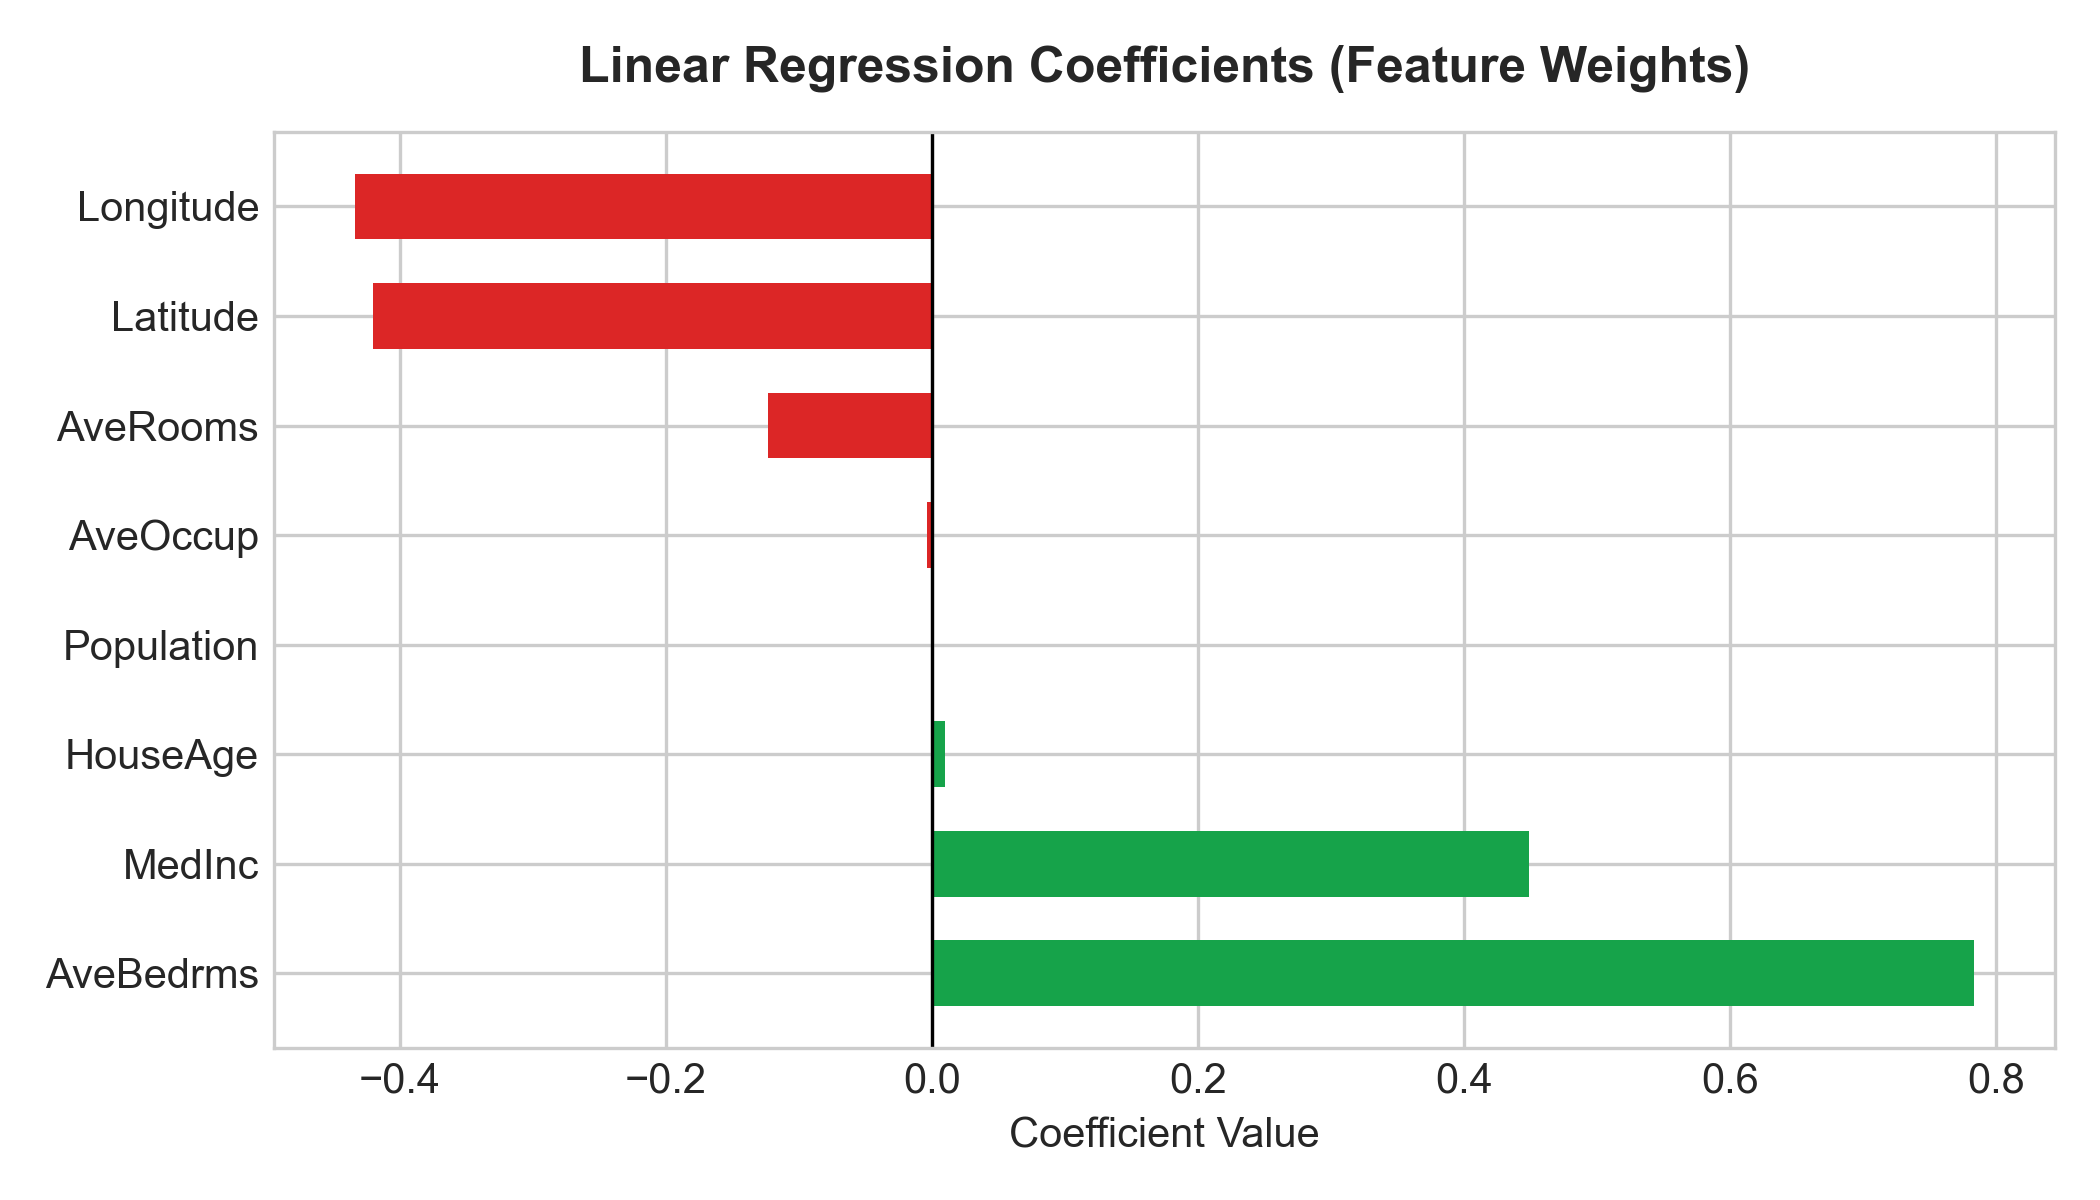

In [8]:
# Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

print(f'Model Intercept (beta_0): {model.intercept_:.4f}\n')
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})
print('Model Coefficients:')
print(coef_df.to_string())

# Plot coefficients
sorted_coef = coef_df.sort_values(by='Coefficient', ascending=False)
plt.figure(figsize=(8, 4), dpi=150)
colors = ['#16a34a' if c > 0 else '#dc2626' for c in sorted_coef['Coefficient']]
plt.barh(sorted_coef['Feature'], sorted_coef['Coefficient'], color=colors, height=0.6)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Linear Regression Coefficients (Feature Weights)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Coefficient Value', fontsize=10)
plt.tight_layout()
plt.show()

### 6. Model Evaluation & Metric Analysis
We evaluate model accuracy on both the training set and unseen test set using three standard regression metrics:
1. **Mean Absolute Error (MAE):** Average magnitude of absolute errors (robust to outliers).
2. **Root Mean Squared Error (RMSE):** Penalizes larger prediction errors quadratically.
3. **Coefficient of Determination ($R^2$):** Proportion of variance in house prices explained by the model.

In [9]:
# Generate predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Calculate metrics
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

print('='*58)
print('               MODEL PERFORMANCE SUMMARY                  ')
print('='*58)
print(f'{"Metric":<28} {"Train Set":<18} {"Test Set":<10}')
print('-'*58)
print(f'{"MAE ($100k)":<28} {train_mae:<18.4f} {test_mae:<10.4f}')
print(f'{"MAE (USD $)":<28} {"$"+f"{train_mae*100000:,.0f}":<18} {"$"+f"{test_mae*100000:,.0f}":<10}')
print(f'{"RMSE ($100k)":<28} {train_rmse:<18.4f} {test_rmse:<10.4f}')
print(f'{"RMSE (USD $)":<28} {"$"+f"{train_rmse*100000:,.0f}":<18} {"$"+f"{test_rmse*100000:,.0f}":<10}')
print(f'{"R² Score":<28} {train_r2:<18.4f} {test_r2:<10.4f}')
print('='*58)
print(f'The test R² of {test_r2:.4f} confirms the linear model explains ~{test_r2*100:.1f}% of the variance in California home prices.')

               MODEL PERFORMANCE SUMMARY                  
Metric                        Train Set          Test Set 
----------------------------------------------------------
MAE ($100k)                      0.5286            0.5332 
MAE (USD $)                     $52,860           $53,320 
RMSE ($100k)                     0.7197            0.7456 
RMSE (USD $)                    $71,970           $74,560 
R² Score                         0.6126            0.5758 
The test R² of 0.5758 confirms the linear model explains ~57.6% of the variance in California home prices.


### 7. Diagnostic Residual Analysis & Error Evaluation
To rigorously validate the linear regression model assumptions, we plot:
1. **Actual vs. Predicted Scatter Plot:** Ideal predictions align directly along the red dashed diagonal ($y = \hat{y}$).
2. **Residuals vs. Predicted Values:** Tests the homoscedasticity assumption (constant error variance).
3. **Residual Distribution Histogram:** Assesses whether errors are normally distributed around zero.

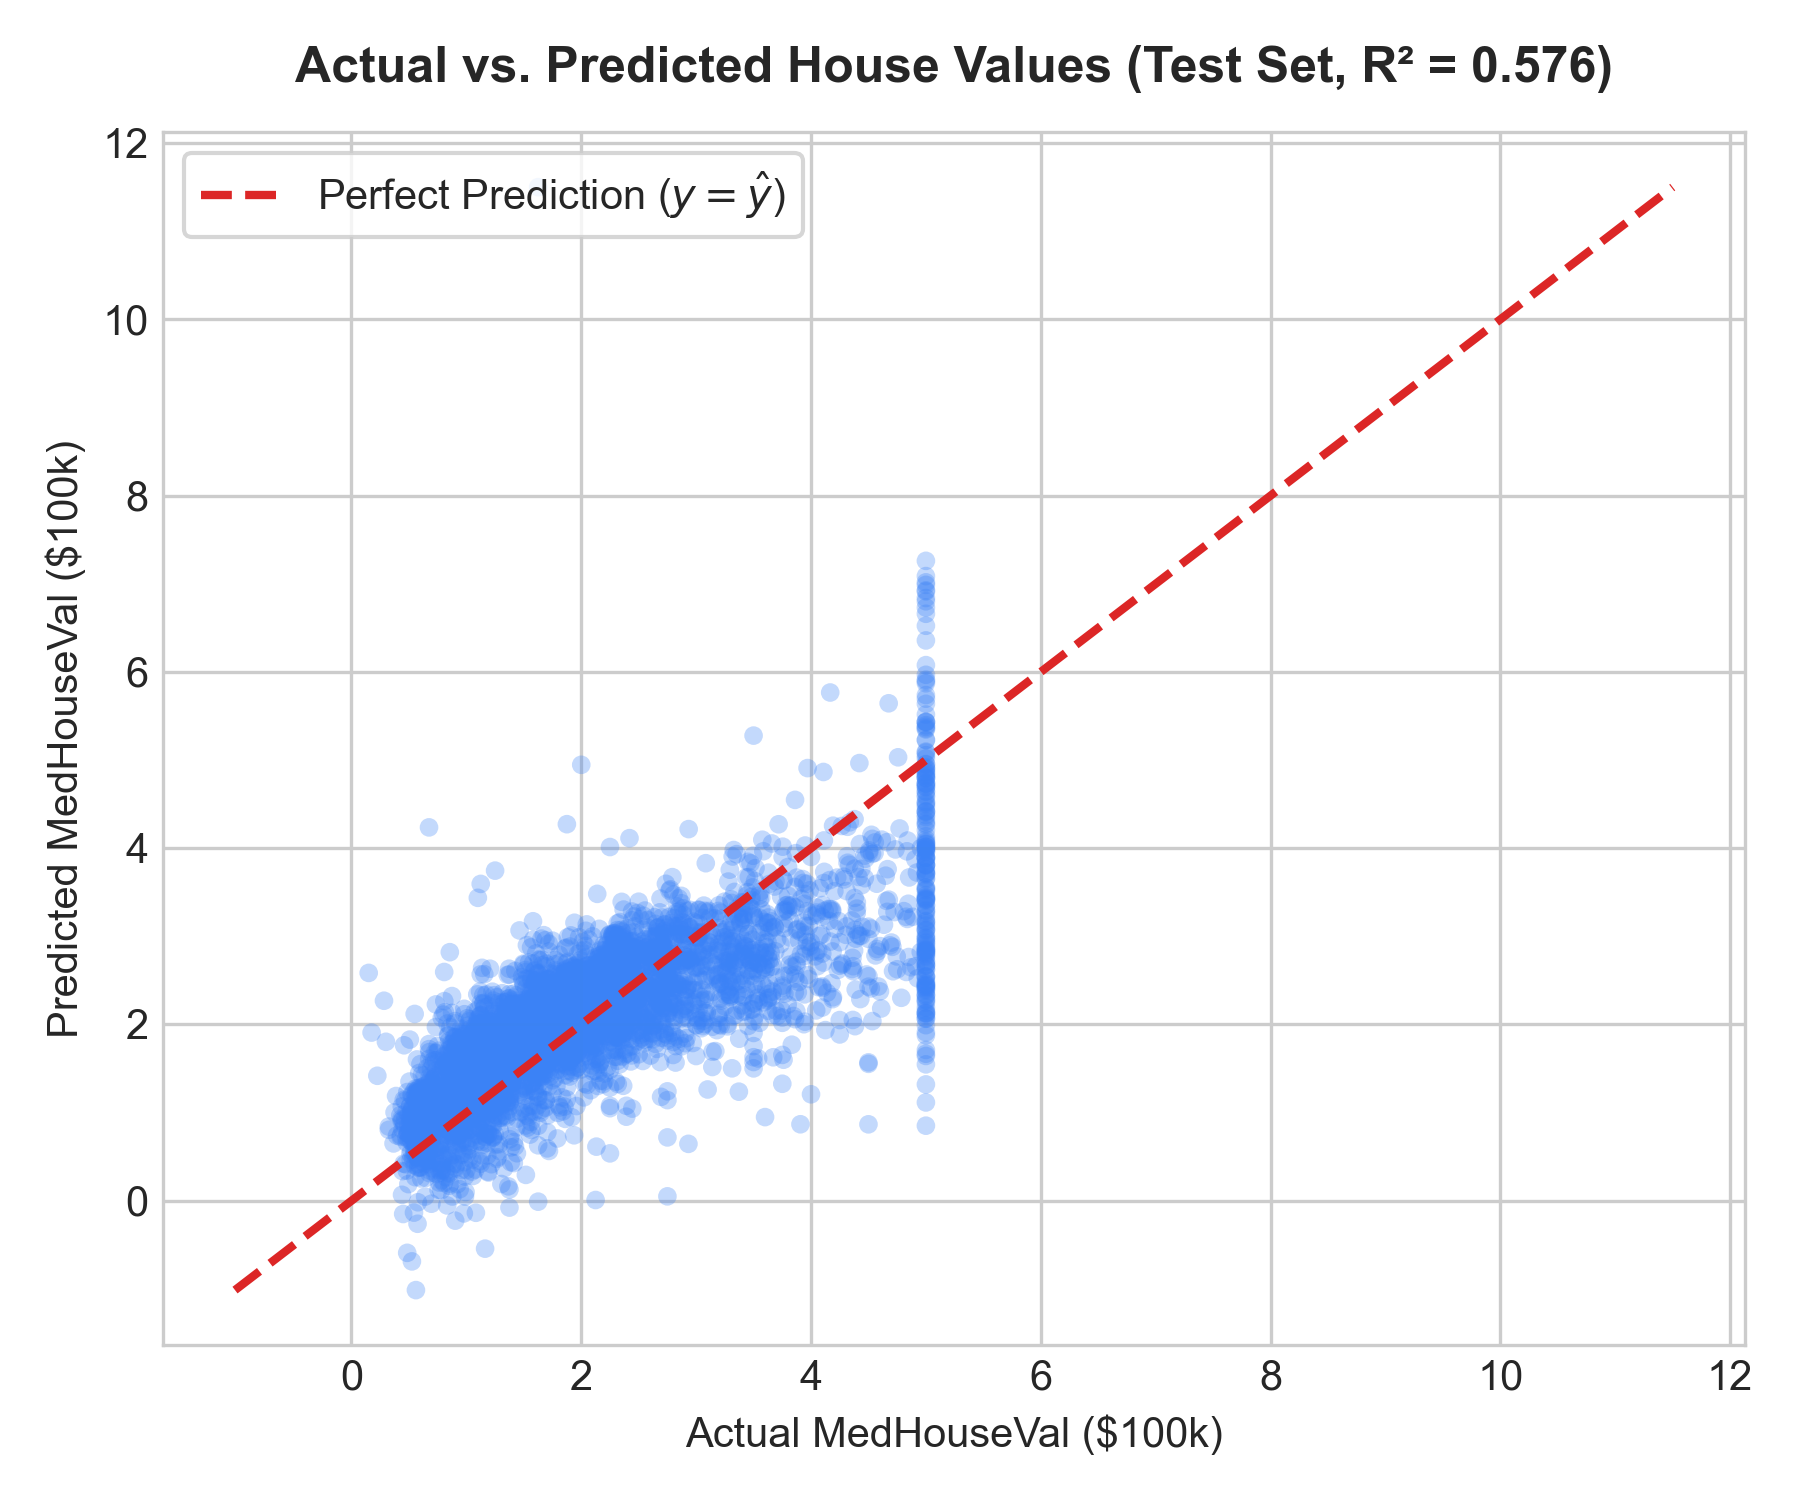

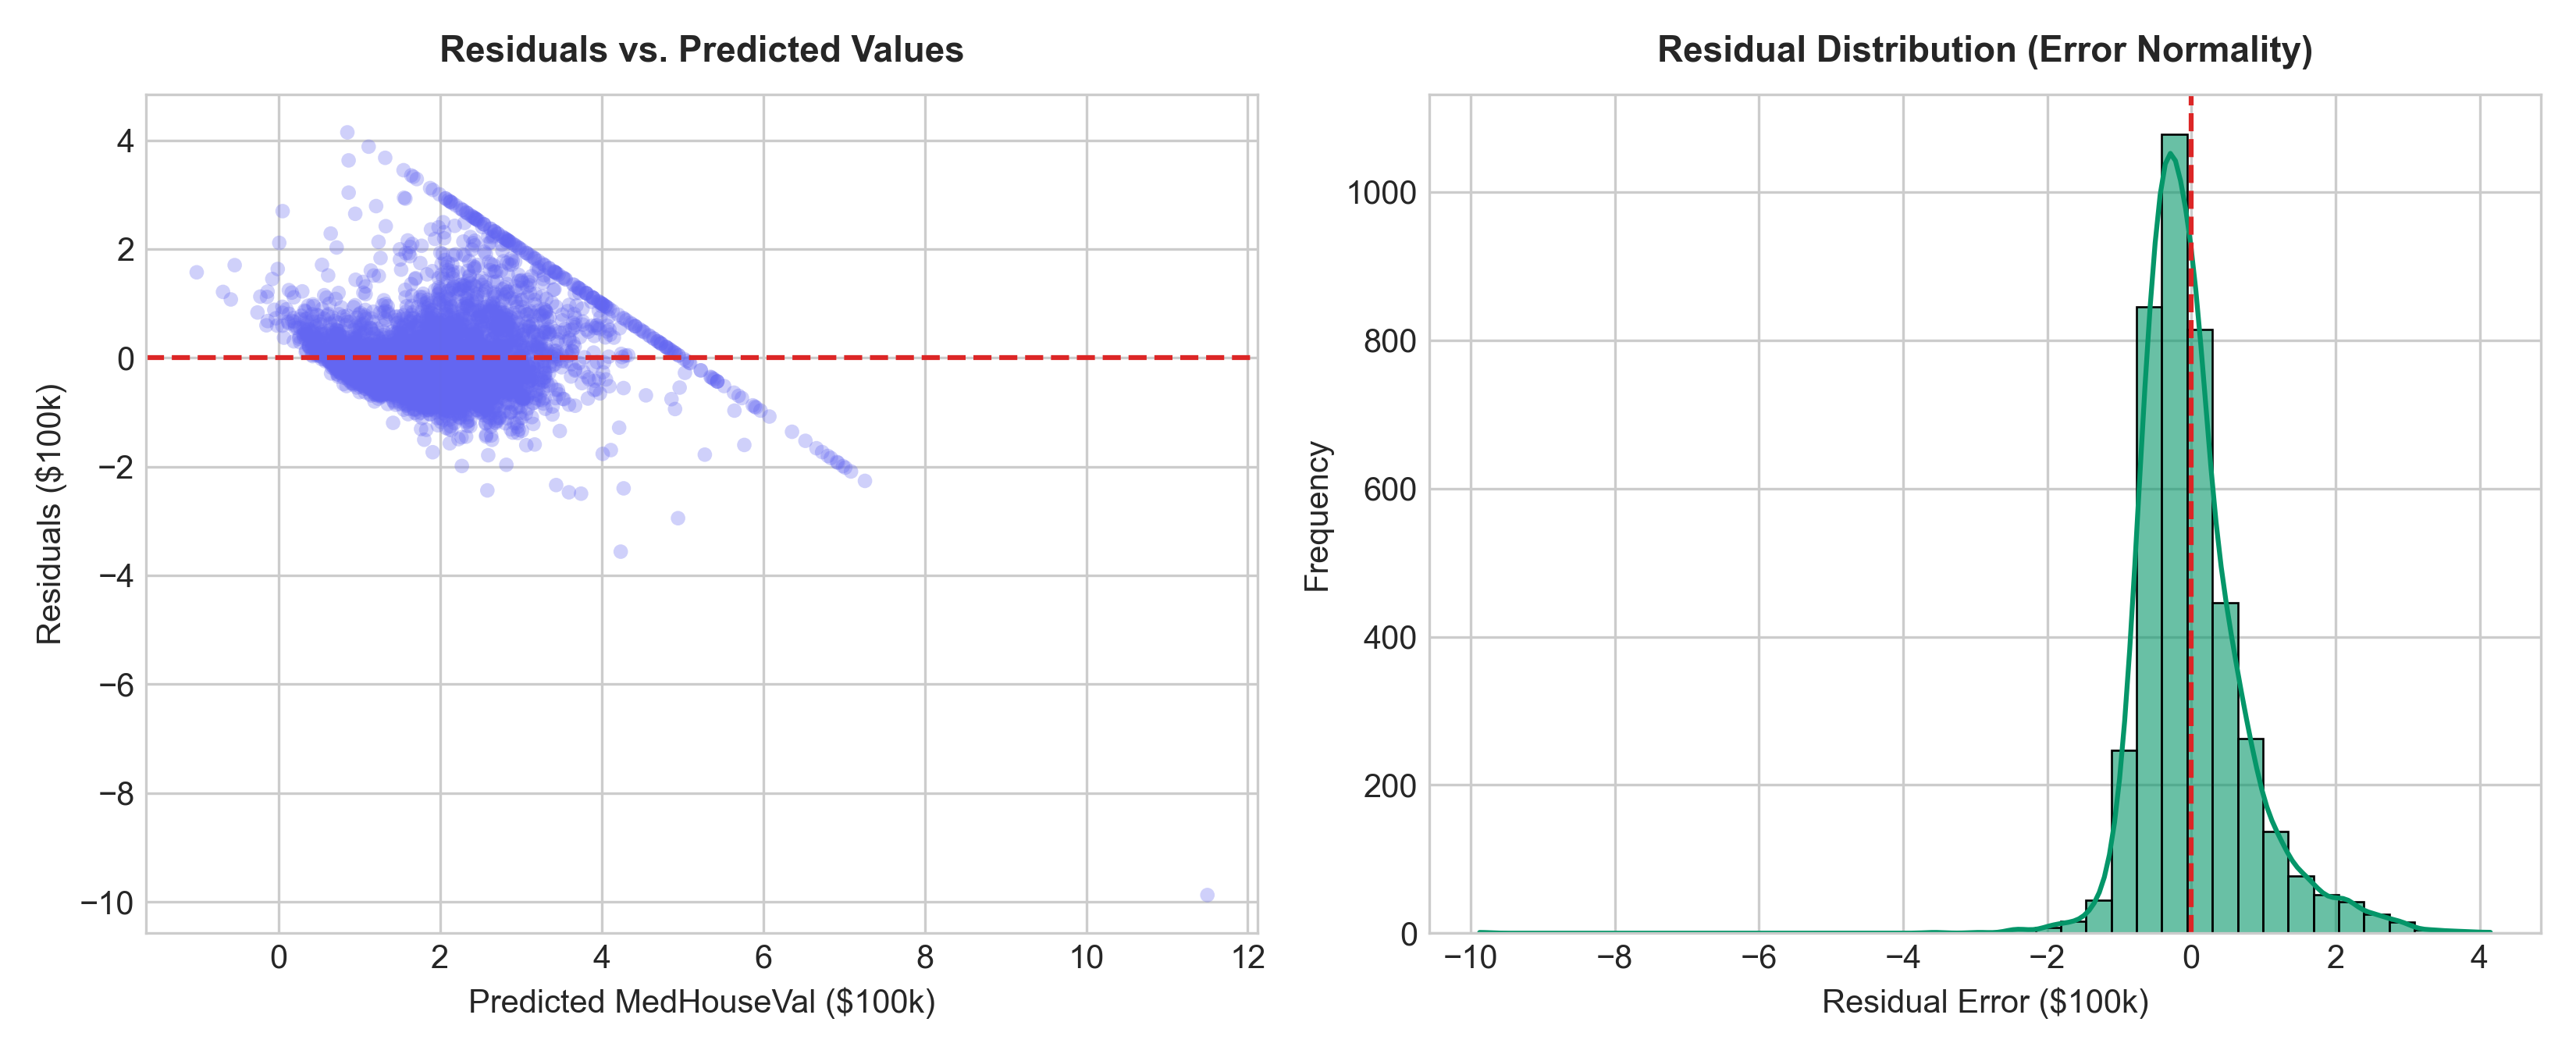

In [10]:
# Actual vs. Predicted Plot
plt.figure(figsize=(7, 6), dpi=150)
plt.scatter(y_test, y_test_pred, alpha=0.35, color='#2563eb', edgecolors='none', s=25)
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='#dc2626', linestyle='--', linewidth=2, label='Ideal Fit ($y=\hat{y}$)')
plt.title(f'Actual vs. Predicted House Values (Test Set, R² = {test_r2:.3f})', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Actual MedHouseVal ($100k)', fontsize=10)
plt.ylabel('Predicted MedHouseVal ($100k)', fontsize=10)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

# Residuals Plot & Distribution
residuals = y_test - y_test_pred
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), dpi=150)

ax1.scatter(y_test_pred, residuals, alpha=0.3, color='#6366f1', edgecolors='none', s=20)
ax1.axhline(0, color='#dc2626', linestyle='--', linewidth=1.5)
ax1.set_title('Residuals vs. Predicted Values', fontsize=11, fontweight='bold', pad=10)
ax1.set_xlabel('Predicted MedHouseVal ($100k)', fontsize=10)
ax1.set_ylabel('Residuals ($100k)', fontsize=10)

sns.histplot(residuals, kde=True, color='#059669', bins=40, ax=ax2, alpha=0.6)
ax2.axvline(0, color='#dc2626', linestyle='--', linewidth=1.5)
ax2.set_title('Residual Distribution (Zero-Centered Normality)', fontsize=11, fontweight='bold', pad=10)
ax2.set_xlabel('Residual Error ($100k)', fontsize=10)
ax2.set_ylabel('Frequency', fontsize=10)

plt.tight_layout()
plt.show()

### 8. Model Export & Live Inference Demonstration
We serialize the trained model to `model.pkl` using `joblib` for deployment, and demonstrate live inference on new test observations.

In [11]:
# Save model to pickle
model_filename = 'model.pkl'
joblib.dump(model, model_filename)
print(f'Model successfully serialized to {model_filename}\n')

# Sample Inference Test
loaded_model = joblib.load(model_filename)
sample_house = pd.DataFrame([{
    'MedInc': 6.5,         # $65,000 median income
    'HouseAge': 25.0,      # 25 years old
    'AveRooms': 6.2,       # 6.2 rooms per house
    'AveBedrms': 1.05,     # 1.05 bedrooms
    'Population': 1200.0,  # 1200 residents
    'AveOccup': 2.8,       # 2.8 people per house
    'Latitude': 37.5,      # Bay Area latitude
    'Longitude': -122.2    # Bay Area longitude
}])

predicted_val = loaded_model.predict(sample_house)[0]
print('=== Sample Inference Test ===')
print('Input District Features:')
print('  Median Income:      $65,000  (MedInc: 6.5)')
print('  Median House Age:   25 years')
print('  Average Rooms:      6.2 rooms/household')
print('  Average Bedrooms:   1.05 bedrooms/household')
print('  Population:         1,200 residents')
print('  Average Occupancy:  2.8 members/household')
print('  Coordinates:        37.5° N, -122.2° W (SF Peninsula)')
print(f'\n--> Predicted Value: ${predicted_val*100000:,.0f} ({predicted_val:.4f} in $100k units)')

Model successfully serialized to model.pkl

=== Sample Inference Test ===
Input District Features:
  Median Income:      $65,000  (MedInc: 6.5)
  Median House Age:   25 years
  Average Rooms:      6.2 rooms/household
  Average Bedrooms:   1.05 bedrooms/household
  Population:         1,200 residents
  Average Occupancy:  2.8 members/household
  Coordinates:        37.5° N, -122.2° W (SF Peninsula)

--> Predicted Value: $314,482 (3.1448 in $100k units)


### 9. Findings, Limitations & Improvement Roadmap

#### Key Findings:
- **Primary Price Driver:** `MedInc` is by far the strongest single linear predictor ($r = 0.69$, coefficient $\approx +0.45$).
- **Geographic Negative Slopes:** Both `Latitude` and `Longitude` show negative coefficients, reflecting coastal premiums where western and southern districts (coastal Southern California and the Bay Area) command higher values.
- **Baseline Accuracy:** The simple linear regression model achieves an $R^2$ of **0.5758** and an MAE of **$53,320** on unseen test data.

#### Model Limitations:
1. **Linearity Assumption:** Housing prices exhibit non-linear geographic and socio-demographic relationships that single plane OLS cannot fully capture.
2. **Target Capping:** The $500,000 ceiling creates an artificial horizontal boundary, causing under-predictions at higher valuations.
3. **Extreme Outliers:** Features such as `AveRooms` (max 141) and `AveOccup` (max 1243) possess extreme outlier districts that skew OLS coefficients.

#### Concrete Next Steps for Improvement:
1. **Feature Engineering:** Create domain-specific ratios such as `rooms_per_household = AveRooms / AveOccup`, `bedrooms_ratio = AveBedrms / AveRooms`, and distance to coast (`coastal_distance`).
2. **Regularized Regression (Ridge & Lasso):** Introduce L1/L2 penalties to mitigate multicollinearity between `AveRooms` and `AveBedrms`.
3. **Polynomial & Interaction Features:** Model non-linear income elasticity and geographic interaction terms (`Latitude * Longitude`).
4. **Non-linear Ensemble Models:** Train Gradient Boosting (`XGBoost`, `LightGBM`) and `RandomForestRegressor`, which typically elevate California housing $R^2$ from **0.58** to **0.83+**.